In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
import os
import crisp


[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:

outdir = "../simulation_figures_package"
sc.settings.figdir = outdir
sc.settings.set_figure_params(facecolor="white", fontsize=18)



 adata_healthy_diseased_merfish.h5ad
 analysis_plots.png
 cell_score_histogram.png
 cell_type_dist_bin1_cell_level.png
 cell_type_dist_bin2_cell_level.png
 code/
 dose_split_h5ad/
 EMT_CC_data/
 EMT_CC.ipynb
 EMT.ipynb
 EMT_TGF.ipynb
 enhanced_analysis_plots.png
 fibrotic_curve_bin1_cell_level.png
 fibrotic_curve_bin2_cell_level.png
 fix_notebook.py
'Framework Overview.pdf'
 Funcs.py
 Functions_explanations
 Gene_level_sim.ipynb
 gft_animation.gif
 Gif_nb.ipynb
 GPU_nb2.ipynb
 GPU_nb.ipynb
'graph examples visualisations.ipynb'
 graph_laplacian_utils.py
 GRCm38_gene_annot.tsv
 GSE213753_RAW/
 GSE213753_RAW.tar
 ideas/
 install_log.txt
 liver_fibrosis_interactions.ipynb
 liver_fibrosis.ipynb
 liver_fibrosis_utils.py
 liver_fibrosis_with_utils.ipynb
 LPOOK.py
 merfish_hepatocytes_zonation.h5ad
 merfish_with_zonation_full.h5ad
 Mice_liver.ipynb
 ok.ipynb
 OSQP_script.py
 pca_rotation.gif
 playgrounds/
 crisp/
 crisp.egg-info/
 __pycache__/
 pyproject.toml
 QP_accelerated.ipynb
 QP.ipynb
 Q

Running for interaction = 0.00
Global projection similarity (circular_label_a vs circular_label_b): 0.5784


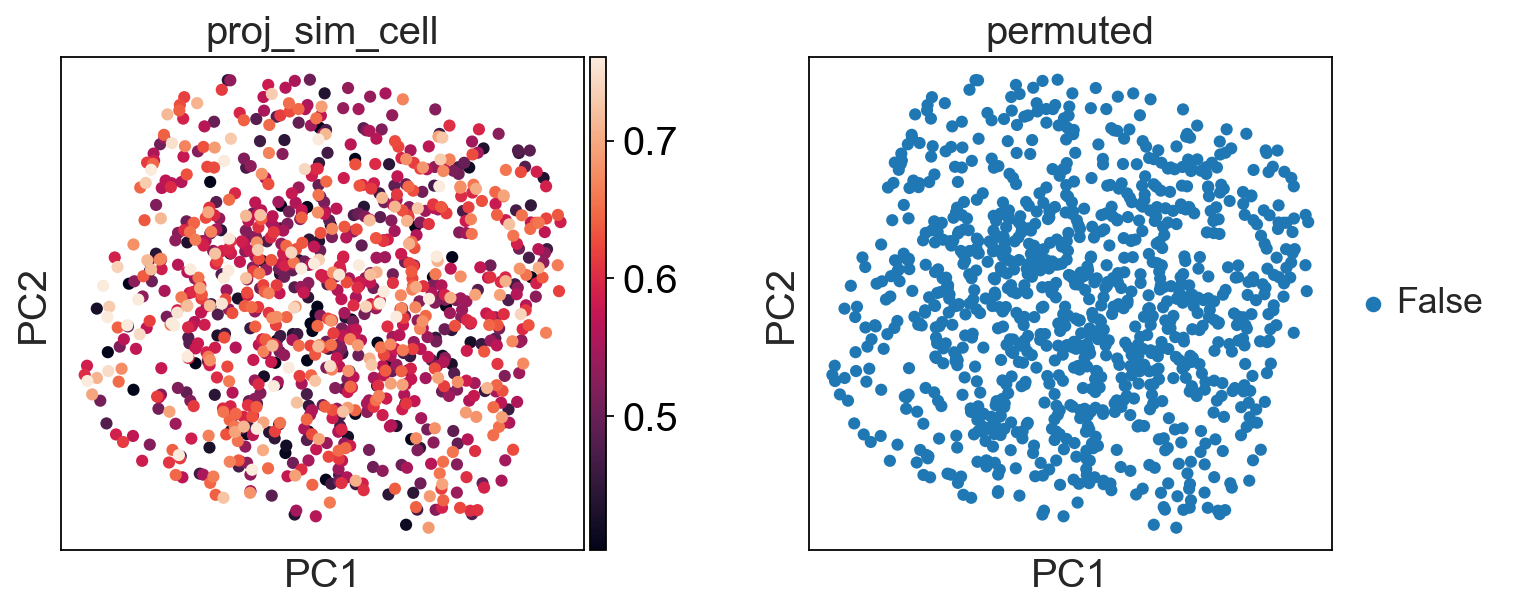

Running for interaction = 0.11
Global projection similarity (circular_label_a vs circular_label_b): 0.5798


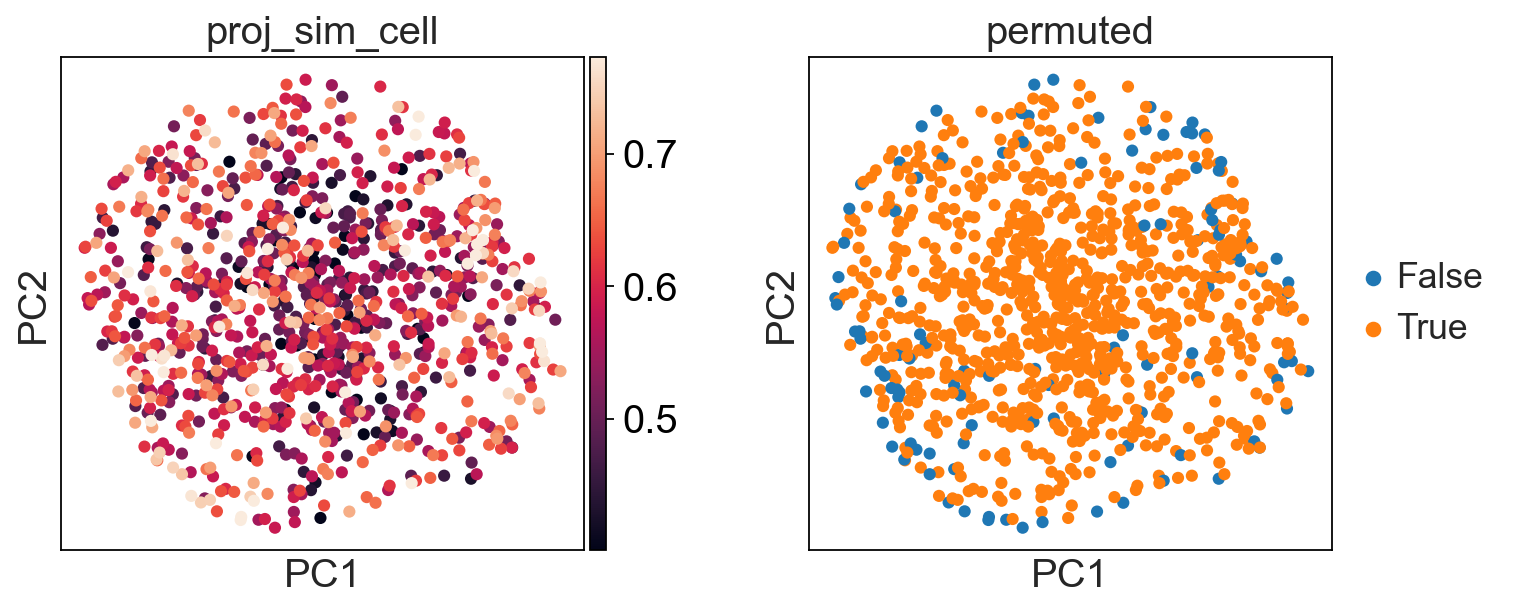

Running for interaction = 0.22
Global projection similarity (circular_label_a vs circular_label_b): 0.6032


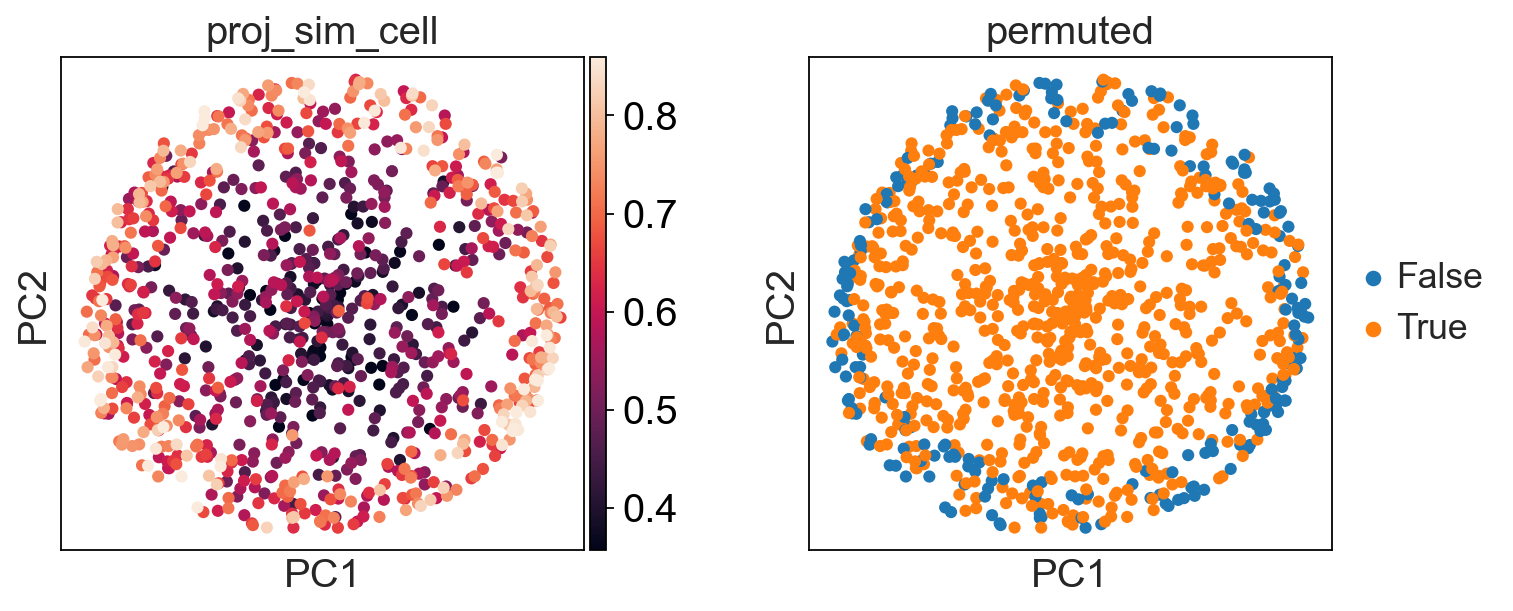

Running for interaction = 0.33
Global projection similarity (circular_label_a vs circular_label_b): 0.6317


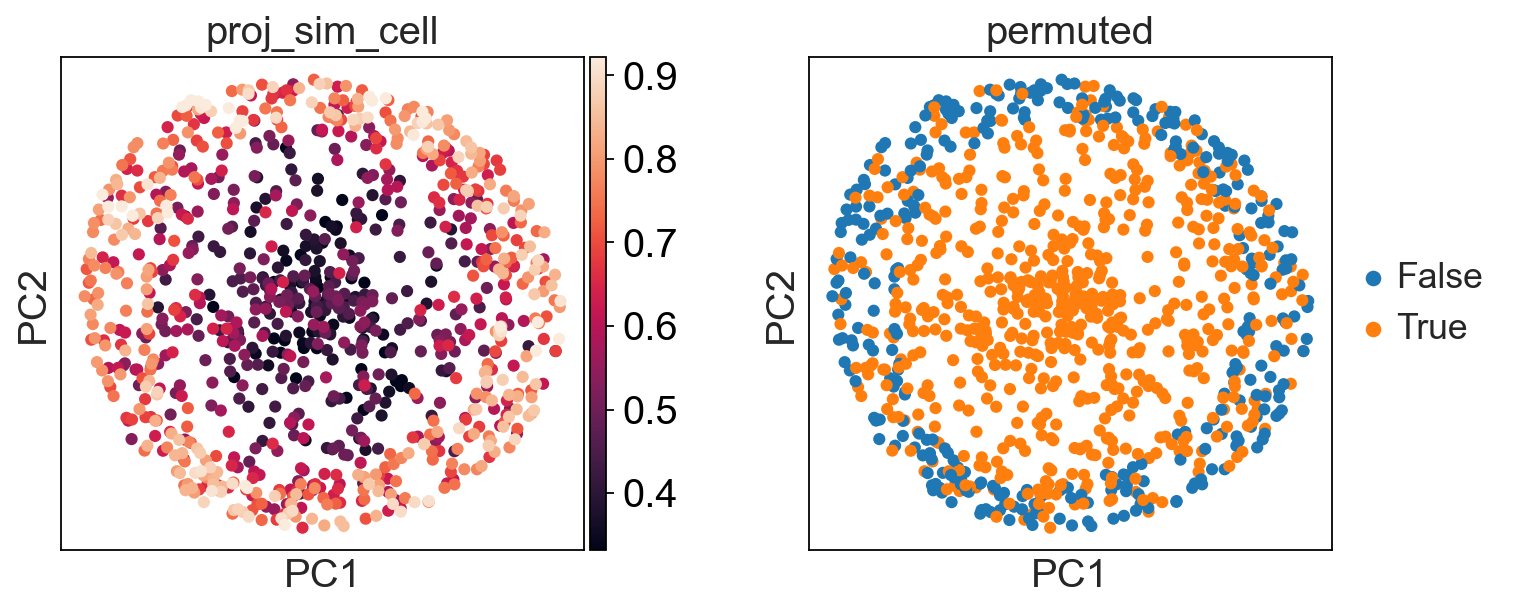

Running for interaction = 0.44
Global projection similarity (circular_label_a vs circular_label_b): 0.6687


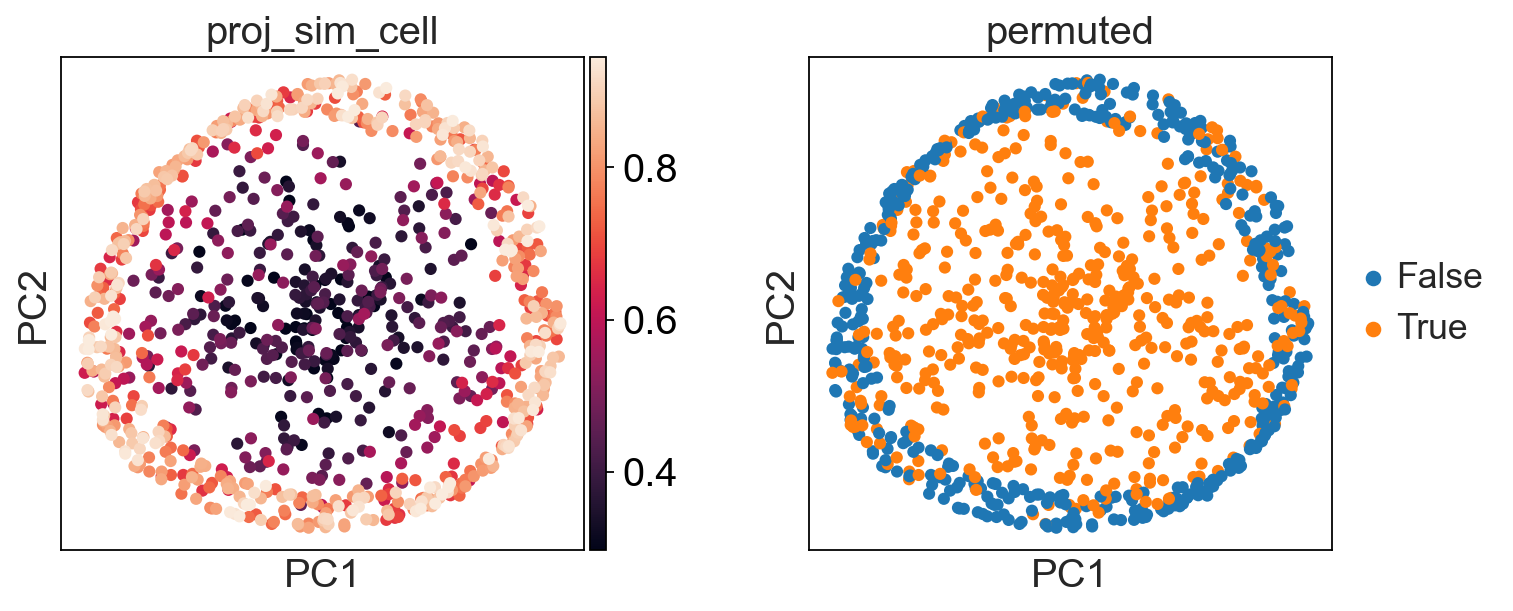

Running for interaction = 0.56
Global projection similarity (circular_label_a vs circular_label_b): 0.7338


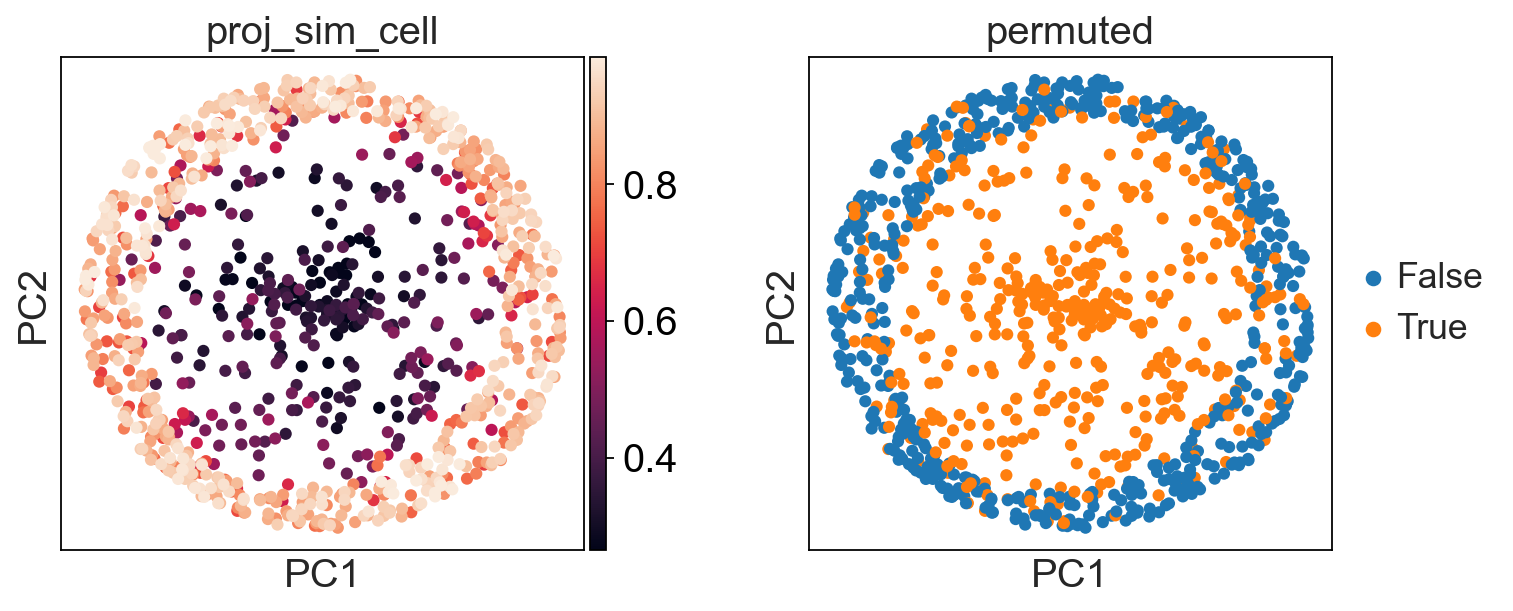

Running for interaction = 0.67
Global projection similarity (circular_label_a vs circular_label_b): 0.7934


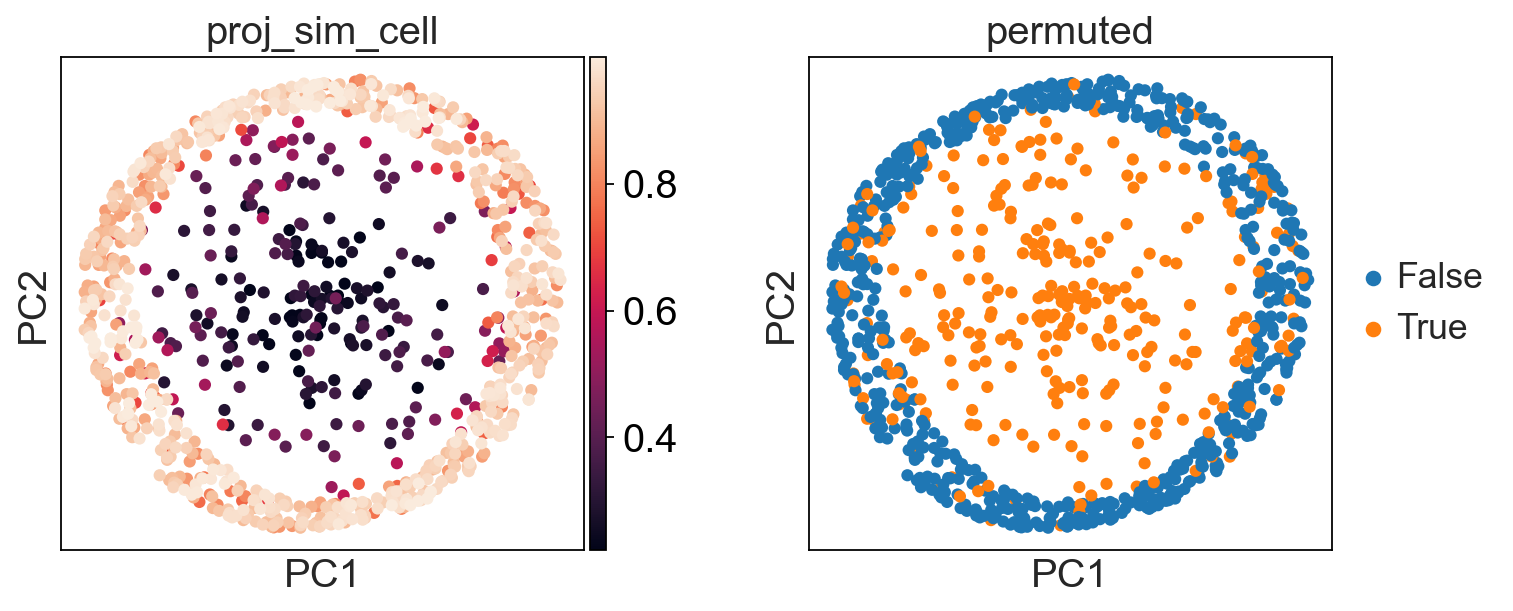

Running for interaction = 0.78
Global projection similarity (circular_label_a vs circular_label_b): 0.8547


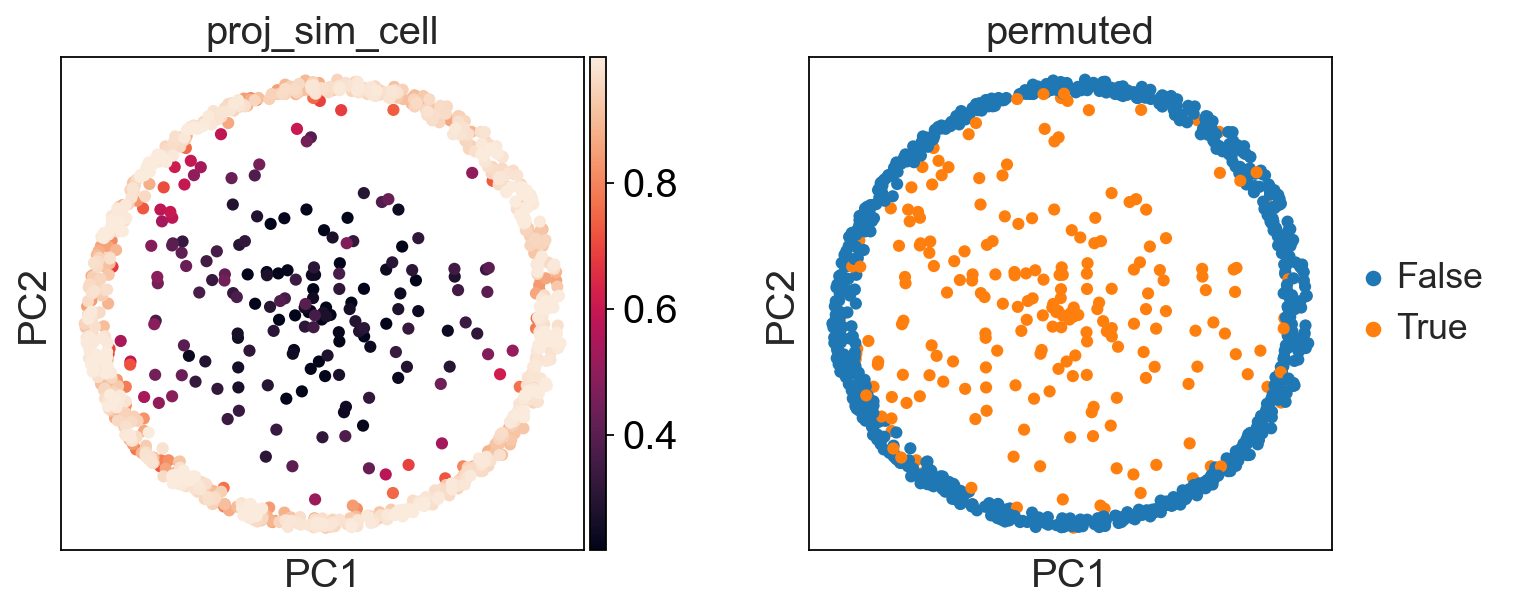

Running for interaction = 0.89
Global projection similarity (circular_label_a vs circular_label_b): 0.9266


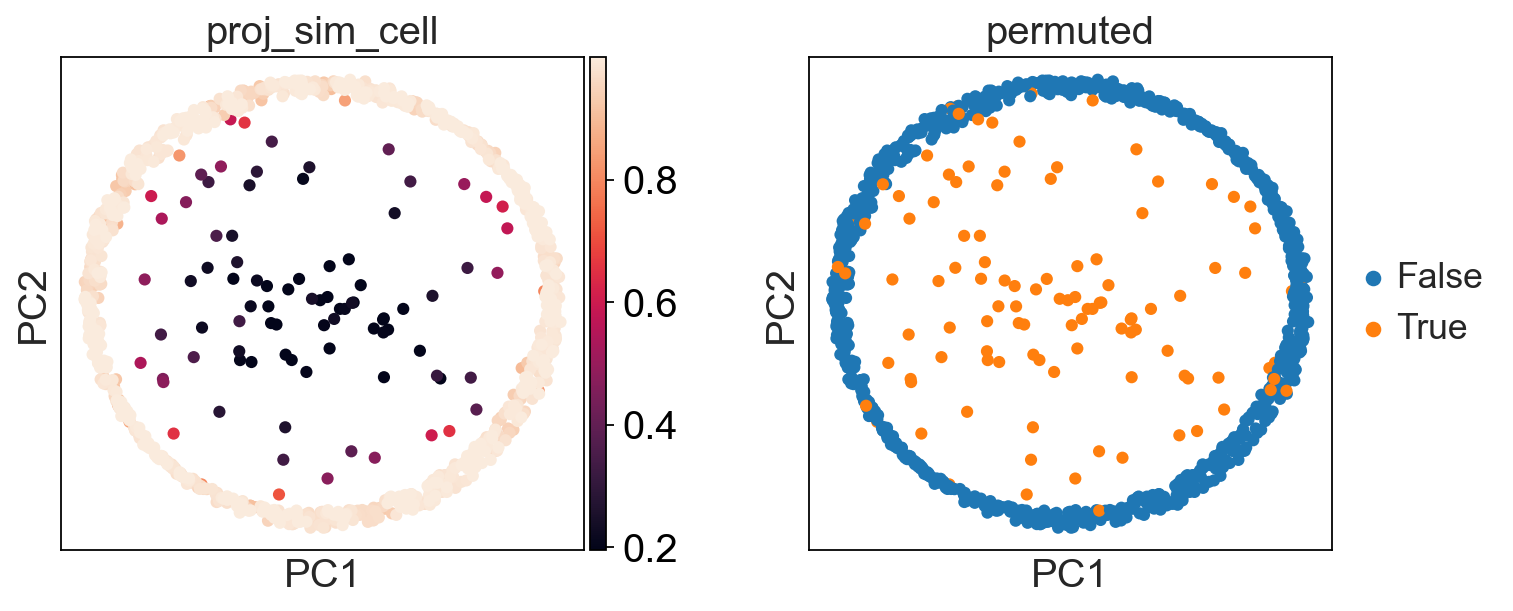

Running for interaction = 1.00
Global projection similarity (circular_label_a vs circular_label_b): 1.0000


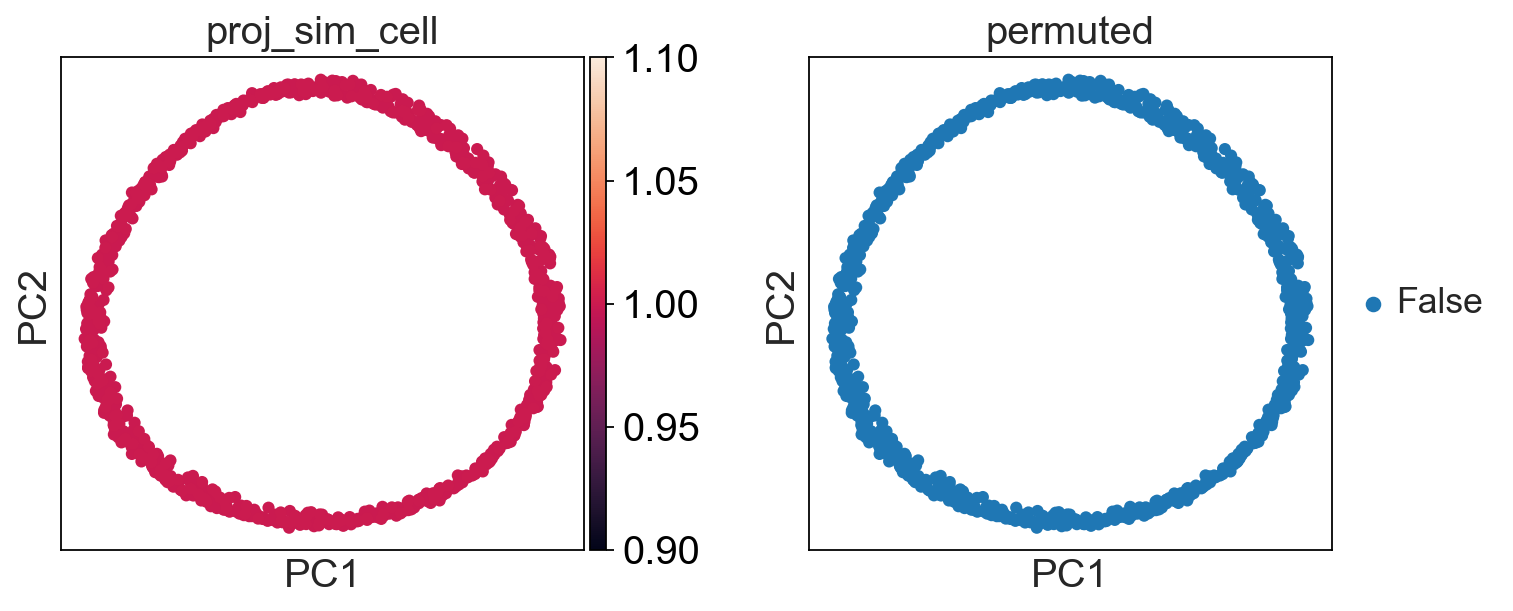

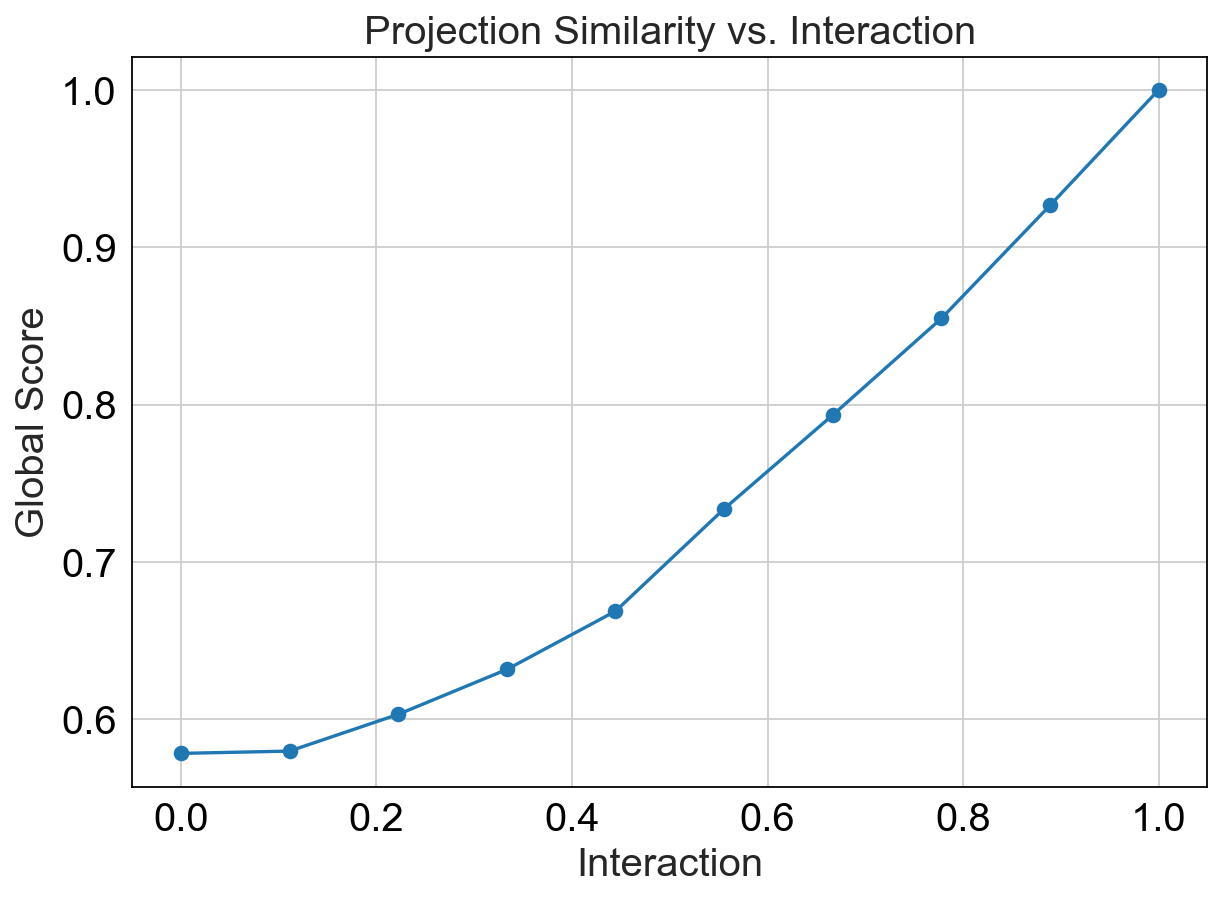

In [3]:
interaction = np.linspace(0, 1, 10)
scores = []
proj_scores = []

for i in interaction:
    print(f"Running for interaction = {i:.2f}")
    subdir = os.path.join(outdir, f"interaction_{i:.2f}")
    os.makedirs(subdir, exist_ok=True)
    sc.settings.figdir = subdir

    adata = crisp.simulate_cyclic(1000, 1000, perm_fraction=1-i, label_perm_fraction=0, n_non_interacting=1000)

    key_a = crisp.encode_circular(adata, "label_a")
    key_b = crisp.encode_circular(adata, "label_b")

    global_score = crisp.compute_projection_similarity(
        adata, key_a, key_b,
        embedding_key="X",
        metric="knn",
    )

    crisp.plot_score_pca(adata, save=f"_pca_proj_sim_cell_{i:.2f}.png")
    if i != 1:
        crisp.plot_score_histogram(
            adata,
            save=os.path.join(subdir, "proj_sim_cell_histogram.png")
        )

    scores.append(global_score)
    proj_scores.append(global_score)

sc.settings.figdir = outdir
plt.figure(figsize=(8, 6))
plt.plot(interaction, scores, marker="o")
plt.title("Projection Similarity vs. Interaction")
plt.xlabel("Interaction")
plt.ylabel("Global Score")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "proj_score_vs_interaction.png"), dpi=300)
plt.show()
